In [1]:
import warnings
warnings.simplefilter("ignore")

import mlflow
import os
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np
from simulation_study_analysis_helpers import *

# move to project root directory to find the mlruns folder with mlflow experiments
notebook_path = Path().resolve()
project_root = notebook_path.parent  # adjust as needed
os.chdir(project_root)

from simulation_studies.generate_synthetic_vine_data import generate_synthetic_vine_data

### Demo on how to analyse MLFlow Stored Experiments

1. Below we move to the root of the project where the mlruns folder is. There we can then call experiment wise run data. MLFlow allows us to look at tags, parameters as well as metrics in a pandas dataframe and hence create plots across runs. See minimal example below.

2. All Tags, Parameters, Metrics and Artifacts (Every Datatype, manely Plots and the Model) can also be viewed using the MLFlow User Interface which is a server you run locally. Simply open a new terminal and run "mlflow ui", then the server runs in that terminal and you can see it in the browser under "http://127.0.0.1:5000" (can be changed by a comand). Server can be closed by closing the terminal and running "pkill -f mlflow" in another terminal.

3. The only annoying thing about mlflow is that is uses absolute instead of relative paths. This means that if you want to analyze results created on another machine (server or another person) then it does not work. However I have coded a workaround that patches the paths. To solve this simply run the python script "/simulation_studies/mlflow_change_mlflow_artifact_directiories.py" in a terminal.


In [46]:
experiment_name = "rvine_20D_2000obs"
experiment = mlflow.get_experiment_by_name(experiment_name) 
df_runs = mlflow.search_runs([experiment.experiment_id])

# subset all runs seed smaller 32
df_runs = df_runs[df_runs["tags.seed_value"].astype(int) < 100]

model fit to true distribution in original samples and bootstrap samples

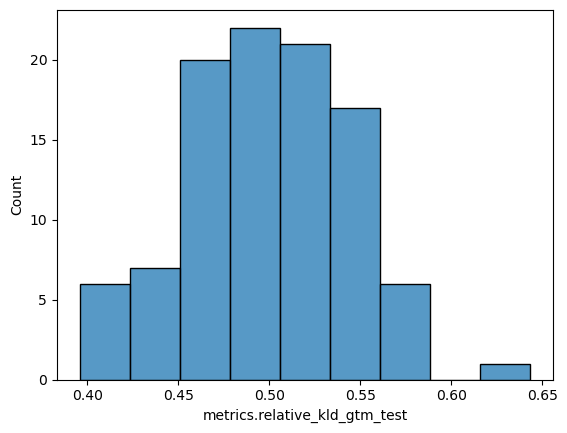

mean  0.49869499999999994
mode  0.4998


In [3]:
sns.histplot(data=df_runs, x="metrics.relative_kld_gtm_test")
plt.show()

print("mean ", df_runs["metrics.relative_kld_gtm_test"].mean())
print("mode ", df_runs["metrics.relative_kld_gtm_test"].quantile(0.5))

check out penalties chosen

(-5.0, 35.0)

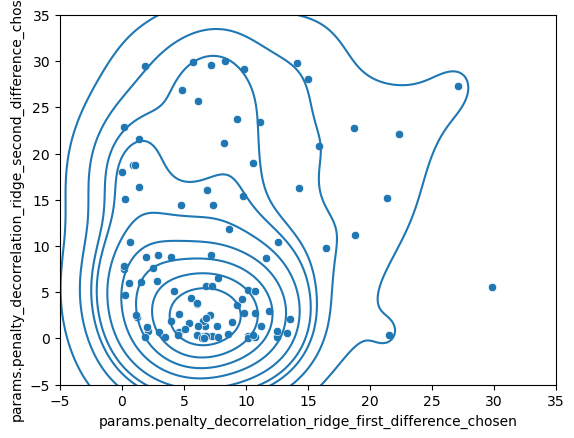

In [4]:
cols = [
    "params.penalty_decorrelation_ridge_first_difference_chosen",
    "params.penalty_decorrelation_ridge_second_difference_chosen",
]
df_runs[cols] = df_runs[cols].astype(float)

sns.kdeplot(data=df_runs, x="params.penalty_decorrelation_ridge_first_difference_chosen", y="params.penalty_decorrelation_ridge_second_difference_chosen")
sns.scatterplot(data=df_runs, x="params.penalty_decorrelation_ridge_first_difference_chosen", y="params.penalty_decorrelation_ridge_second_difference_chosen")
plt.ylim(-5,35)
plt.xlim(-5,35)

## Training and Validation Samples based Analysis: Likelihood Ratio Statistic

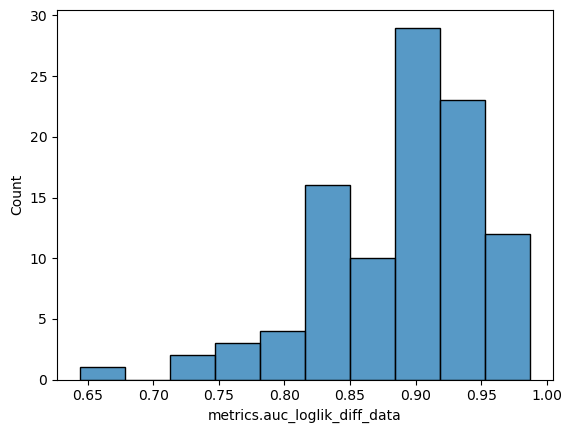

mean  0.8891271786492375
mode  0.9079520697167756


In [5]:
sns.histplot(data=df_runs, x="metrics.auc_loglik_diff_data")
plt.show()

print("mean ", df_runs["metrics.auc_loglik_diff_data"].mean())
print("mode ", df_runs["metrics.auc_loglik_diff_data"].quantile(0.5))

In [6]:
df_runs["metrics.auc_iae"]

0     0.982979
1     0.980937
2     0.999319
3     0.977397
4     0.969771
        ...   
95    0.991966
96    0.992511
97    0.967865
98    0.966231
99    0.986928
Name: metrics.auc_iae, Length: 100, dtype: float64

In [7]:
seed_value = seed_value_copula = 0

synthetic_data_dict = generate_synthetic_vine_data(
        seed_value=seed_value,
        seed_value_copula=seed_value_copula,
        dimensionality=20,
        Independence_tree=3,
        vine_type="R-Vine",
        N_train=1600,
        N_validate=400,
        N_test=20000,
        tau_mean=0.3, 
        tau_range=0.2, 
        negative_tau=True
    )

In [8]:
true = np.array(synthetic_data_dict["df_true_structure"]["dependence"])
baseline_predictor = np.zeros(true.shape)

In [42]:
from sklearn.metrics import roc_auc_score, matthews_corrcoef, average_precision_score, accuracy_score, precision_score

In [10]:
roc_auc_score(true, baseline_predictor)

0.5

In [20]:
baseline_predictor_slightly_better = baseline_predictor.copy()
baseline_predictor_slightly_better[0:4] = 0.3

In [12]:
roc_auc_score(true, baseline_predictor_slightly_better)

0.537037037037037

In [24]:
average_precision_score(true, baseline_predictor_slightly_better)

0.33723196881091616

In [34]:
matthews_corrcoef(true, baseline_predictor)

0.0

In [40]:
accuracy_score(true, baseline_predictor_slightly_better)

ValueError: Classification metrics can't handle a mix of binary and continuous targets

In [15]:
df_runs

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.kld_vine_oracle_test,metrics.auc_iae,metrics.auc_normed_hessian_val,metrics.auc_kld,...,tags.seed_value_copula,tags.mlflow.source.name,tags.tau_range,tags.bootstrap_warpspeed,tags.tau_mean,tags.N_test,tags.seed_value,tags.vine_type,tags.negative_tau,tags.Independence_tree
0,9e92d93ba1e94df9a5c4c081fd9276f3,160667409790832329,FINISHED,file:///Users/matthiasherp/Desktop/phd_github_...,2026-06-13 09:39:33.358000+00:00,2026-06-13 09:51:49.592000+00:00,0.0373,0.982979,0.974946,0.990877,...,99,/mnt/simulation_studies/run_files_paper/run_ex...,0.2,False,0.3,20000,99,R-Vine,True,3
1,a403aeeca4814cddb22036dab7327ce1,160667409790832329,FINISHED,file:///Users/matthiasherp/Desktop/phd_github_...,2026-06-13 09:27:52.255000+00:00,2026-06-13 09:39:33.348000+00:00,0.0831,0.980937,0.965414,0.964733,...,98,/mnt/simulation_studies/run_files_paper/run_ex...,0.2,False,0.3,20000,98,R-Vine,True,3
2,a519eafb95c1488fb5d20c5fb13b91fc,160667409790832329,FINISHED,file:///Users/matthiasherp/Desktop/phd_github_...,2026-06-13 09:17:44.844000+00:00,2026-06-13 09:27:52.239000+00:00,0.0622,0.999319,0.986111,0.999047,...,97,/mnt/simulation_studies/run_files_paper/run_ex...,0.2,False,0.3,20000,97,R-Vine,True,3
3,8d571507f10541e5b7db54a406310010,160667409790832329,FINISHED,file:///Users/matthiasherp/Desktop/phd_github_...,2026-06-13 09:08:22.019000+00:00,2026-06-13 09:17:44.835000+00:00,0.0831,0.977397,0.960784,0.977533,...,96,/mnt/simulation_studies/run_files_paper/run_ex...,0.2,False,0.3,20000,96,R-Vine,True,3
4,add1cb26dd284593991f96db2d2cba49,160667409790832329,FINISHED,file:///Users/matthiasherp/Desktop/phd_github_...,2026-06-13 08:58:11.040000+00:00,2026-06-13 09:08:22.007000+00:00,0.0588,0.969771,0.941721,0.959014,...,95,/mnt/simulation_studies/run_files_paper/run_ex...,0.2,False,0.3,20000,95,R-Vine,True,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,73e3aba40f69417cb3746b24e0e5e638,160667409790832329,FINISHED,file:///Users/matthiasherp/Desktop/phd_github_...,2026-06-12 15:41:19.895000+00:00,2026-06-12 15:51:57.341000+00:00,0.0547,0.991966,0.949891,0.988017,...,4,/mnt/simulation_studies/run_files_paper/run_ex...,0.2,False,0.3,20000,4,R-Vine,True,3
96,ceb0349476ee4fd6ae7482b53b9d6af4,160667409790832329,FINISHED,file:///Users/matthiasherp/Desktop/phd_github_...,2026-06-12 15:30:46.020000+00:00,2026-06-12 15:41:19.884000+00:00,0.1133,0.992511,0.921160,0.972222,...,3,/mnt/simulation_studies/run_files_paper/run_ex...,0.2,False,0.3,20000,3,R-Vine,True,3
97,73e3bbb1f3304fecbd4e2d6d6823bd21,160667409790832329,FINISHED,file:///Users/matthiasherp/Desktop/phd_github_...,2026-06-12 15:20:41.732000+00:00,2026-06-12 15:30:46.008000+00:00,0.0499,0.967865,0.953568,0.958742,...,2,/mnt/simulation_studies/run_files_paper/run_ex...,0.2,False,0.3,20000,2,R-Vine,True,3
98,1e65ef4f9ac64472b3f7269121fc86fb,160667409790832329,FINISHED,file:///Users/matthiasherp/Desktop/phd_github_...,2026-06-12 15:09:41.363000+00:00,2026-06-12 15:20:41.712000+00:00,0.0938,0.966231,0.947712,0.951389,...,1,/mnt/simulation_studies/run_files_paper/run_ex...,0.2,False,0.3,20000,1,R-Vine,True,3


In [43]:
import pandas as pd
import numpy as np
from sklearn.metrics import matthews_corrcoef
import os

def load_artifact_csv(artifact_uri: str, filename: str) -> pd.DataFrame:
    """Convert mlflow artifact URI to local path and load CSV."""
    # Strip the file:// prefix
    local_path = artifact_uri.replace("file://", "")
    full_path = os.path.join(local_path, filename)
    return pd.read_csv(full_path)


def compute_mcc_for_run(row: pd.Series, filename: str = "conditional_independence_table_model_samples.csv") -> dict:
    """Load artifact CSV for a run and compute MCC for IAE and normed_hessian_abs_mean."""
    
    result = {
        "run_id": row["run_id"],
        "mcc_iae": np.nan,
        "mcc_hessian": np.nan,
        "n_pairs": np.nan,
        "prevalence": np.nan,
    }
    
    try:
        df = load_artifact_csv(row["artifact_uri"], filename)
        
        # ── Validate required columns exist ──────────────────────────────────
        required_cols = ["dependence", "iae", "normed_hessian_abs_mean"]
        missing = [c for c in required_cols if c not in df.columns]
        if missing:
            print(f"[WARN] Run {row['run_id']}: missing columns {missing}")
            return result
        
        # ── Ground truth binary label ─────────────────────────────────────────
        y_true = df["dependence"].astype(int).values  # 0 = independent, 1 = dependent
        
        result["n_pairs"]    = len(y_true)
        result["prevalence"] = y_true.mean()
        
        # ── IAE score ────────────────────────────────────────────────
        y_pred_iae = df["iae"]
        result["score_iae"] = average_precision_score(y_true, y_pred_iae)
        
        iae_opt = compute_optimal_mcc(y_true, y_pred_iae)
        result["mcc_iae_optimal"]       = iae_opt["optimal_mcc"]
        result["acc_iae_optimal"] = iae_opt["optimal_acc"]
        result["pc_iae_optimal"] = iae_opt["optimal_pc"]
        
        # ── Hessian score ────────────────────────────────────────────
        y_pred_hessian = df["normed_hessian_abs_mean"]
        result["score_hessian"] = average_precision_score(y_true, y_pred_hessian)
        
        hess_opt = compute_optimal_mcc(y_true, y_pred_hessian)
        result["mcc_hessian_optimal"]       = hess_opt["optimal_mcc"]
        result["acc_hessian_optimal"] = hess_opt["optimal_acc"]
        result["pc_hessian_optimal"] = hess_opt["optimal_pc"]
        
    except FileNotFoundError:
        print(f"[ERROR] Run {row['run_id']}: file not found at {row['artifact_uri']}")
    except Exception as e:
        print(f"[ERROR] Run {row['run_id']}: {e}")
    
    return result


def compute_optimal_mcc(y_true: np.ndarray, y_score: np.ndarray) -> dict:
    """
    Compute MCC at the optimal threshold by sweeping all unique score values.
    
    Returns
    -------
    dict with optimal_mcc, optimal_threshold, and full sweep results
    """
    thresholds = np.unique(y_score)
    
    mccs = []
    accs = []
    pcs = []
    for thresh in thresholds:
        y_pred = (y_score >= thresh).astype(int)
        
        # Edge case: all same prediction → MCC undefined (= 0)
        if len(np.unique(y_pred)) < 2:
            mccs.append(0.0)
            accs.append(0.0)
            pcs.append(0.0)
        else:
            mccs.append(matthews_corrcoef(y_true, y_pred))
            accs.append(accuracy_score(y_true, y_pred))
            pcs.append(precision_score(y_true, y_pred))
    
    mccs = np.array(mccs)
    best_idx = np.argmax(mccs)
    
    accs = np.array(accs)
    best_idx = np.argmax(accs)
    
    pcs = np.array(pcs)
    best_idx = np.argmax(pcs)
    
    return {
        "optimal_mcc":       mccs[best_idx],
        "optimal_acc":       accs[best_idx],
        "optimal_pc":       pcs[best_idx],
    }


# ── Main loop ─────────────────────────────────────────────────────────────────
results = []

df = df_runs

for idx, row in df.iterrows():
    #print(f"Processing row {idx} | run_id: {row['run_id'][:8]}...")
    res = compute_mcc_for_run(row)
    results.append(res)

results_df = pd.DataFrame(results)

# ── Summary ───────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("MCC Summary across runs")
print("="*60)
print(results_df[["score_iae", "score_hessian", "mcc_iae_optimal", "mcc_hessian_optimal", "acc_iae_optimal", "mcc_hessian_optimal", "pc_iae_optimal", "pc_hessian_optimal" ]].describe().round(4))
print(f"Mean prevalence:  {results_df['prevalence'].mean():.4f}")


MCC Summary across runs
       score_iae  score_hessian  mcc_iae_optimal  mcc_hessian_optimal  \
count   100.0000       100.0000         100.0000             100.0000   
mean      0.9763         0.9432           0.9059               0.8425   
std       0.0131         0.0280           0.0467               0.0683   
min       0.9402         0.8548           0.7276               0.6319   
25%       0.9680         0.9254           0.8841               0.8065   
50%       0.9798         0.9444           0.9098               0.8519   
75%       0.9843         0.9633           0.9355               0.8841   
max       1.0000         0.9894           1.0000               0.9613   

       acc_iae_optimal  mcc_hessian_optimal  pc_iae_optimal  \
count         100.0000             100.0000           100.0   
mean            0.9616               0.8425             1.0   
std             0.0191               0.0683             0.0   
min             0.8895               0.6319             1.0   
25

In [58]:
auc_ggm = np.load('simulation_studies/ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy')

In [61]:
df_runs["metrics.auc_iae"]

0     0.982979
1     0.980937
2     0.999319
3     0.977397
4     0.969771
        ...   
95    0.991966
96    0.992511
97    0.967865
98    0.966231
99    0.986928
Name: metrics.auc_iae, Length: 100, dtype: float64

In [62]:
df_runs["metrics.auc_normed_hessian"]

0     0.971269
1     0.965959
2     0.988017
3     0.970180
4     0.943083
        ...   
95    0.958742
96    0.928241
97    0.956155
98    0.937636
99    0.981209
Name: metrics.auc_normed_hessian, Length: 100, dtype: float64

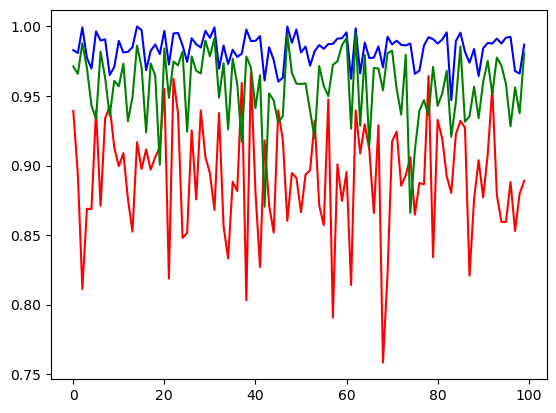

In [72]:
plt.plot(auc_ggm, color="red")
plt.plot(df_runs["metrics.auc_iae"], color="blue")
plt.plot(df_runs["metrics.auc_normed_hessian"], color="green")

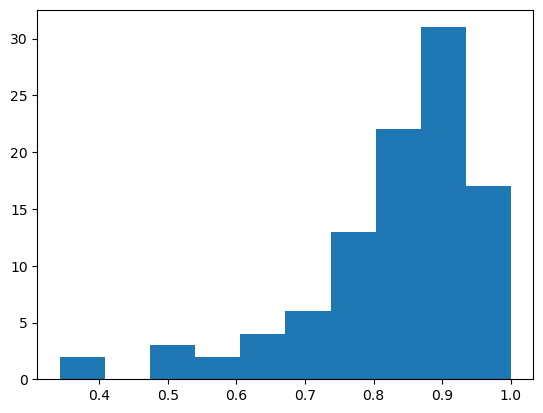

In [80]:
plt.hist(((np.array(df_runs["metrics.auc_iae"]) - auc_ggm) / [1 - auc_ggm]).flatten())
plt.show()

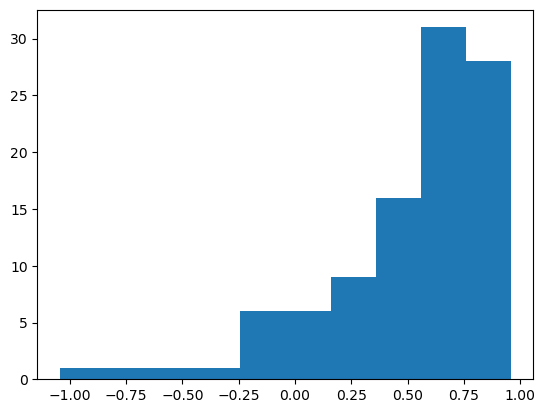

In [82]:
plt.hist(((np.array(df_runs["metrics.auc_normed_hessian"]) - auc_ggm) / [1 - auc_ggm]).flatten())
plt.show()

In [50]:
experiment_name

'rvine_20D_2000obs'

In [48]:
os.getcwd()

'/Users/matthiasherp/Desktop/phd_github_repositories/gtm'